In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_features=10, 
    n_samples=1000, 
    n_informative=4,
    n_redundant=6,
    n_repeated=0,
    n_classes=2, 
    random_state=42
)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

### Train a Logistic Regression Model

In [2]:
from sklearn.metrics import classification_report

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.66      0.69      0.67       122
           1       0.69      0.66      0.68       128

    accuracy                           0.68       250
   macro avg       0.68      0.68      0.68       250
weighted avg       0.68      0.68      0.68       250



Let's assume above is the classification model for pneumonia detection. In this case, a recall of 0.66 for positive class is pretty bad because out of 100 psenumonia patients you are detecting the disease only in 66 and to remaining 34 patients you are saying you don't have a disease. We would like to increase this number even though it comes at the cost of increased false positives (i.e. telling a person that you have pneumonia, when in reality they don't).

Reduce the probability threshold to 0.4 (from a default of 0.5) to capture more cases of pneumonia

In [6]:
model.predict_proba(X_test) # [0th class, class 1]

array([[0.42177413, 0.57822587],
       [0.47264857, 0.52735143],
       [0.47450714, 0.52549286],
       [0.57633106, 0.42366894],
       [0.86158446, 0.13841554],
       [0.87686618, 0.12313382],
       [0.53116907, 0.46883093],
       [0.24051733, 0.75948267],
       [0.9374641 , 0.0625359 ],
       [0.64131341, 0.35868659],
       [0.88767897, 0.11232103],
       [0.16271705, 0.83728295],
       [0.10467321, 0.89532679],
       [0.17340534, 0.82659466],
       [0.54010799, 0.45989201],
       [0.8152776 , 0.1847224 ],
       [0.32879368, 0.67120632],
       [0.76833198, 0.23166802],
       [0.55202253, 0.44797747],
       [0.80392898, 0.19607102],
       [0.52965666, 0.47034334],
       [0.05023713, 0.94976287],
       [0.87745375, 0.12254625],
       [0.39354259, 0.60645741],
       [0.31598737, 0.68401263],
       [0.30845928, 0.69154072],
       [0.25426846, 0.74573154],
       [0.64554533, 0.35445467],
       [0.28633177, 0.71366823],
       [0.76399808, 0.23600192],
       [0.

#### Change the thresold to see how precision, recall changes

In [8]:
probabilities= model.predict_proba(X_test)[:,1] #for class 1
y_pred=(probabilities>0.4).astype(int)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.75      0.57      0.65       122
           1       0.67      0.82      0.74       128

    accuracy                           0.70       250
   macro avg       0.71      0.70      0.69       250
weighted avg       0.71      0.70      0.70       250



In [13]:
from sklearn.metrics import roc_curve

fpr,tpr,threshold=roc_curve(y_test,probabilities) #for different thres levels it gives the corresponding tpr & fpr
fpr[:5],tpr[:5],threshold[:5]

(array([0.        , 0.        , 0.        , 0.00819672, 0.00819672]),
 array([0.       , 0.0078125, 0.265625 , 0.265625 , 0.2890625]),
 array([       inf, 0.97928246, 0.80890214, 0.80840719, 0.80207033]))

In [15]:
tpr

array([0.       , 0.0078125, 0.265625 , 0.265625 , 0.2890625, 0.2890625,
       0.296875 , 0.296875 , 0.34375  , 0.34375  , 0.3515625, 0.3515625,
       0.375    , 0.375    , 0.3984375, 0.3984375, 0.4296875, 0.4296875,
       0.4375   , 0.4375   , 0.4609375, 0.4609375, 0.46875  , 0.46875  ,
       0.4765625, 0.4765625, 0.484375 , 0.484375 , 0.4921875, 0.4921875,
       0.5078125, 0.5078125, 0.515625 , 0.515625 , 0.5390625, 0.5390625,
       0.5546875, 0.5546875, 0.5859375, 0.5859375, 0.625    , 0.625    ,
       0.640625 , 0.640625 , 0.6484375, 0.6484375, 0.65625  , 0.65625  ,
       0.71875  , 0.71875  , 0.75     , 0.75     , 0.7578125, 0.7578125,
       0.765625 , 0.765625 , 0.7734375, 0.7734375, 0.7890625, 0.7890625,
       0.796875 , 0.796875 , 0.84375  , 0.84375  , 0.8515625, 0.8515625,
       0.859375 , 0.859375 , 0.8671875, 0.8671875, 0.875    , 0.875    ,
       0.8828125, 0.8828125, 0.890625 , 0.890625 , 0.90625  , 0.90625  ,
       0.9140625, 0.9140625, 0.921875 , 0.921875 , 

In [20]:
desired_recall=0.9
#as there is no exactly 0.9 so we will see closest to 0.9 and get the index of that
closest_index=np.argmin(abs(tpr-desired_recall))
closest_index

np.int64(76)

In [22]:
# now we have the index of tpr which is closest to 0.9 now we will find its coresponding threshholdabs
threshold[76],tpr[76]

(np.float64(0.26349585272229664), np.float64(0.90625))

In [23]:

y_pred=(probabilities>0.26).astype(int)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.74      0.28      0.40       122
           1       0.57      0.91      0.70       128

    accuracy                           0.60       250
   macro avg       0.65      0.59      0.55       250
weighted avg       0.65      0.60      0.56       250



In [24]:
from sklearn.metrics import auc

area=auc(fpr,tpr)
area

0.764856557377049

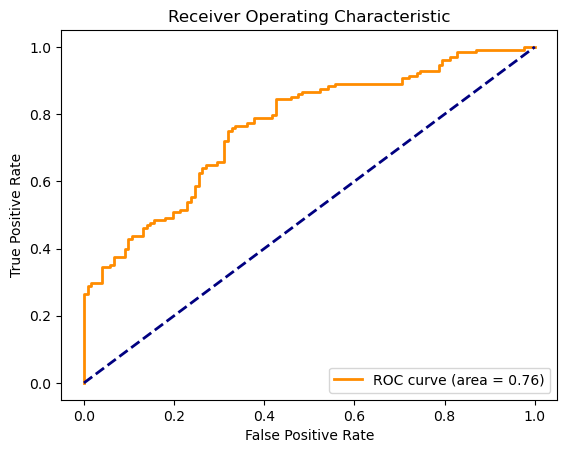

In [26]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
# plt.xlim([0.0, 1.0])
# plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

In [27]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

model = XGBClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.89      0.94      0.92       122
           1       0.94      0.89      0.92       128

    accuracy                           0.92       250
   macro avg       0.92      0.92      0.92       250
weighted avg       0.92      0.92      0.92       250



In [28]:
probabilities_xgb = model.predict_proba(X_test)[:,1]
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, probabilities_xgb)

fpr_xgb[:5], tpr_xgb[:5], thresholds_xgb[:5]

(array([0.        , 0.        , 0.        , 0.00819672, 0.00819672]),
 array([0.       , 0.0078125, 0.078125 , 0.078125 , 0.1328125]),
 array([       inf, 0.9999684 , 0.9999354 , 0.99991846, 0.99987686],
       dtype=float32))

In [29]:
area2=auc(fpr_xgb,tpr_xgb)
area2

0.9505635245901639

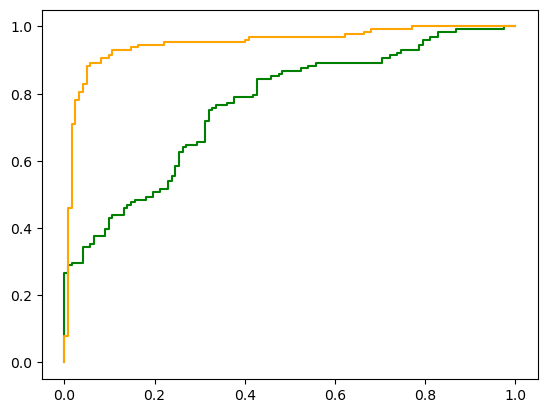

In [32]:
plt.plot(fpr,tpr,color='green')
plt.plot(fpr_xgb,tpr_xgb,color='orange')

In [40]:
desired_recall=0.95
closest_index=np.argmin(abs(desired_recall-tpr_xgb))
closest_index

np.int64(30)

In [41]:
thresholds_xgb[closest_index],fpr_xgb[closest_index]

(np.float32(0.04414873), np.float64(0.22131147540983606))

In [43]:
y_pred=probabilities_xgb>0.04
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.94      0.77      0.85       122
           1       0.81      0.95      0.88       128

    accuracy                           0.86       250
   macro avg       0.88      0.86      0.86       250
weighted avg       0.88      0.86      0.86       250

